<a href="https://colab.research.google.com/github/KellyLee818/KellyLee818.github.io/blob/main/2026_10_14_UNHP_Hands_On_Activity_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as py
import pandas as pd

In [ ]:
url = "https://raw.githubusercontent.com/yongmeiwang/AI_BigData_CancerBiology/main/Data/gtex_integrin_7_organs.xlsx"
Gtex_integrin = pd.read_excel(url)
Gtex_integrin.head()

,Unnamed: 0,primary_site,ITGA10,ITGAD,ITGAM,ITGA3,ITGBL1,ITGAE,ITGA2,ITGB3,...,ITGA6,ITGA2B,ITGB1,ITGAL,ITGA9,ITGB5,ITGA8,ITGA4,ITGA1,ITGA11
0,GTEX-13QIC-0011-R1a-SM-5O9CJ,Brain,0.5763,-6.5064,2.2573,0.7832,1.0363,4.6035,2.5731,-2.8262,...,2.8562,1.3846,5.8430,1.1316,-0.7108,3.5387,-0.0725,-0.4521,0.2029,-2.8262
1,GTEX-1399S-1726-SM-5L3DI,Lung,4.9137,-3.6259,4.7307,7.1584,1.7702,4.9556,1.9149,2.6067,...,4.2412,4.1211,7.7256,4.4900,2.9281,6.1483,5.1867,2.6185,4.7856,-0.0277
2,GTEX-PWCY-1326-SM-48TCU,Ovary,2.3953,-5.0116,1.4547,4.2593,-0.7346,4.4149,0.2642,1.5216,...,3.6816,1.5465,7.2964,-0.9406,2.7742,5.0414,2.0325,0.7579,2.2573,1.2516
3,GTEX-QXCU-0626-SM-2TC69,Lung,4.0541,-2.3147,4.5053,7.5651,4.1788,4.1772,5.3695,1.8444,...,4.9631,1.9149,7.9947,3.3911,2.8462,6.7683,4.1636,2.7951,5.3284,1.2147
4,GTEX-ZA64-1526-SM-5CVMD,Breast,2.0569,-2.4659,3.3993,3.1311,3.0074,4.4977,-1.7809,2.7139,...,4.7340,0.6332,7.3496,-0.9406,2.5338,6.5696,1.7229,-0.6416,3.1195,1.1050


In [ ]:
Gtex_integrin.shape

(1987, 29)

In [ ]:
Gtex_lung_brain_data = Gtex_integrin[Gtex_integrin['primary_site'].isin(['Lung', 'Brain'])]
Gtex_lung_brain_data.head()

,Unnamed: 0,primary_site,ITGA10,ITGAD,ITGAM,ITGA3,ITGBL1,ITGAE,ITGA2,ITGB3,...,ITGA6,ITGA2B,ITGB1,ITGAL,ITGA9,ITGB5,ITGA8,ITGA4,ITGA1,ITGA11
0,GTEX-13QIC-0011-R1a-SM-5O9CJ,Brain,0.5763,-6.5064,2.2573,0.7832,1.0363,4.6035,2.5731,-2.8262,...,2.8562,1.3846,5.8430,1.1316,-0.7108,3.5387,-0.0725,-0.4521,0.2029,-2.8262
1,GTEX-1399S-1726-SM-5L3DI,Lung,4.9137,-3.6259,4.7307,7.1584,1.7702,4.9556,1.9149,2.6067,...,4.2412,4.1211,7.7256,4.4900,2.9281,6.1483,5.1867,2.6185,4.7856,-0.0277
3,GTEX-QXCU-0626-SM-2TC69,Lung,4.0541,-2.3147,4.5053,7.5651,4.1788,4.1772,5.3695,1.8444,...,4.9631,1.9149,7.9947,3.3911,2.8462,6.7683,4.1636,2.7951,5.3284,1.2147
5,GTEX-11EI6-0826-SM-5985V,Lung,6.0732,-2.4659,3.9901,7.3945,4.7688,5.1157,4.3356,2.3366,...,3.7378,4.7247,7.5016,5.1396,2.5036,6.5443,4.6531,3.8136,5.8679,0.7407
6,GTEX-S341-0326-SM-2XCAU,Lung,4.2510,-5.0116,3.3076,6.1715,3.1129,5.2954,2.2960,1.1184,...,4.7104,2.7530,7.5022,4.0730,2.6325,6.0483,5.0562,2.6962,5.1611,0.9343


In [ ]:
Gtex_lung_brain_data.shape

(1440, 29)

In [ ]:
Gtex_lung_brain_data['primary_site'].value_counts()

,count
primary_site,
Brain,1152
Lung,288


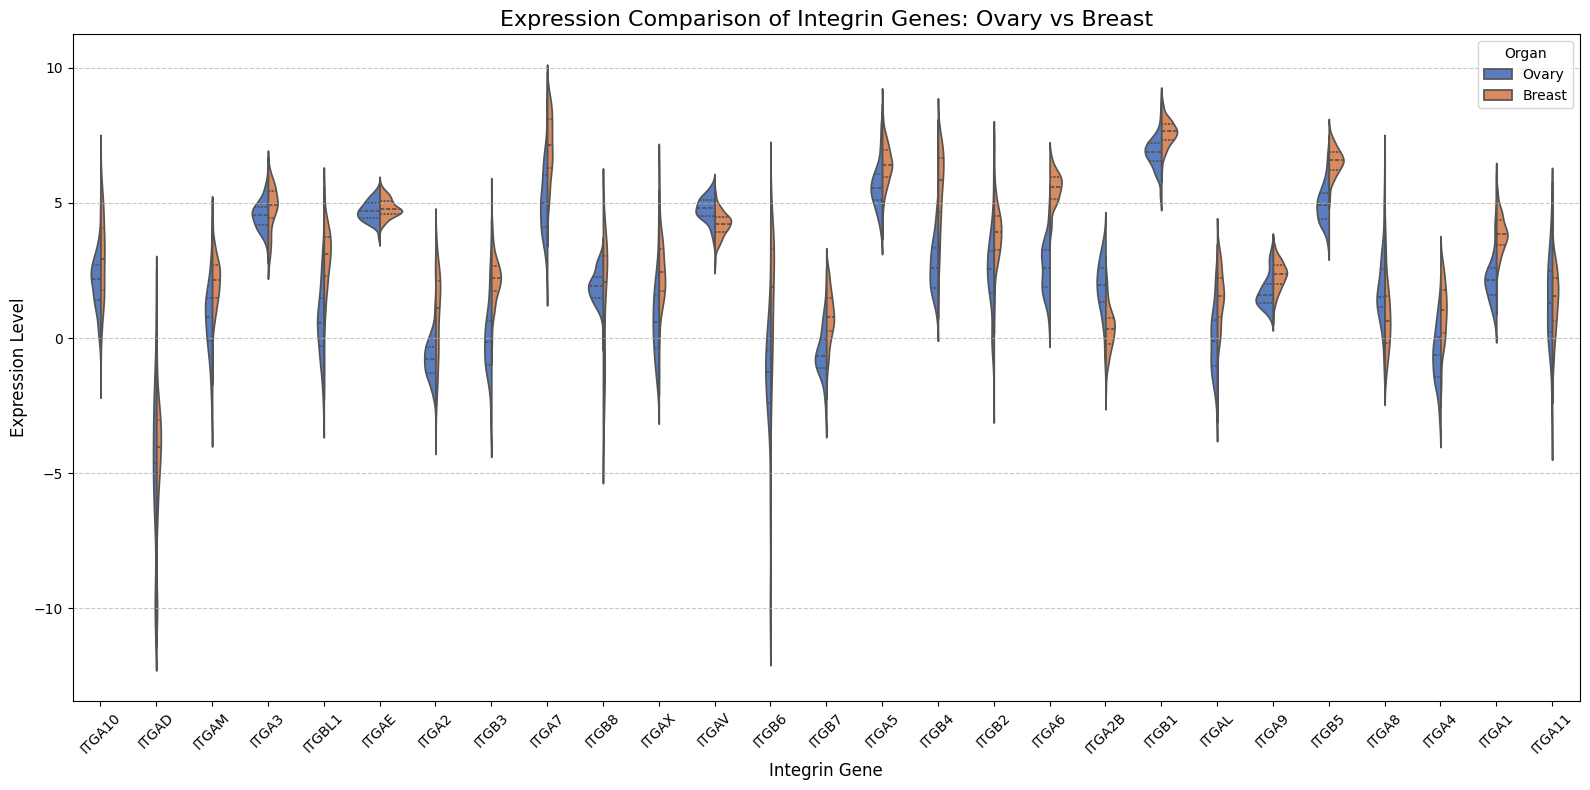

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter the data for 'Ovary' and 'Breast' organs if not already done
ovary_breast_data = Gtex_integrin[Gtex_integrin['primary_site'].isin(['Ovary', 'Breast'])]

# Identify all the integrin columns (columns starting with 'ITG')
integrin_cols = [col for col in ovary_breast_data.columns if col.startswith('ITG')]

# Melt the DataFrame to create a long-form format suitable for seaborn plotting
melted_data = ovary_breast_data.melt(
    id_vars=['primary_site'],
    value_vars=integrin_cols,
    var_name='Integrin Gene',
    value_name='Expression'
)

# Create the violin plot
plt.figure(figsize=(16, 8))
sns.violinplot(
    data=melted_data,
    x='Integrin Gene',
    y='Expression',
    hue='primary_site',
    split=True,
    inner='quart',
    palette='muted'
)

plt.title('Expression Comparison of Integrin Genes: Ovary vs Breast', fontsize=16)
plt.xlabel('Integrin Gene', fontsize=12)
plt.ylabel('Expression Level', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Organ')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# Ensure we have the ovary and breast subset
ovary_breast_data = Gtex_integrin[Gtex_integrin['primary_site'].isin(['Ovary', 'Breast'])]

# Prepare features (X) using only 'ITGA1' and target (y) as the 'primary_site'
X = ovary_breast_data[['ITGA1']]
y = ovary_breast_data['primary_site']

# Split the dataset into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Initialize and train the Logistic Regression model
model = LogisticRegression()
model.fit(X_train, y_train)

# Make predictions on the unseen test set
y_pred = model.predict(X_test)

# Calculate the accuracy of the predictions
accuracy = accuracy_score(y_test, y_pred)

# Create a comparison DataFrame for actual vs predicted labels
comparison_df = pd.DataFrame({
    'True Label': y_test,
    'Predicted Label': y_pred
}).reset_index(drop=True)

# Display the results
print(f"Model Accuracy on Test Set: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

print("\nFirst 10 True vs. Predicted Labels:")
display(comparison_df.head(10))

Model Accuracy on Test Set: 0.9074

Classification Report:
              precision    recall  f1-score   support

      Breast       0.90      0.97      0.93        36
       Ovary       0.93      0.78      0.85        18

    accuracy                           0.91        54
   macro avg       0.92      0.88      0.89        54
weighted avg       0.91      0.91      0.91        54


First 10 True vs. Predicted Labels:


,True Label,Predicted Label
0,Breast,Breast
1,Breast,Breast
2,Ovary,Ovary
3,Breast,Breast
4,Breast,Breast
5,Breast,Breast
6,Breast,Breast
7,Ovary,Ovary
8,Breast,Breast
9,Breast,Breast


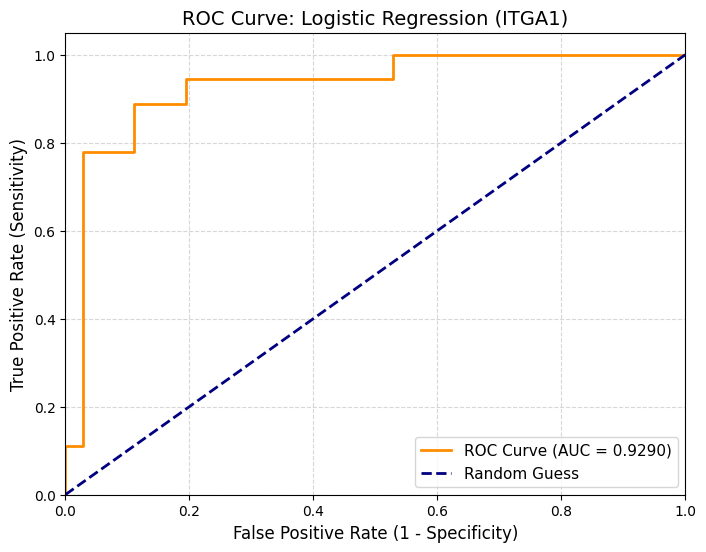

In [28]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Get prediction probabilities for the positive class ('Ovary')
# Since model.classes_ shows the order of classes, let's identify the index of 'Ovary'
ovary_index = list(model.classes_).index('Ovary')
y_probs = model.predict_proba(X_test)[:, ovary_index]

# Map the true labels to binary (1 for 'Ovary', 0 for 'Breast')
y_test_binary = y_test.map({'Breast': 0, 'Ovary': 1})

# Calculate ROC metrics
fpr, tpr, thresholds = roc_curve(y_test_binary, y_probs)
auc_score = roc_auc_score(y_test_binary, y_probs)

# Plot the ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
plt.title('ROC Curve: Logistic Regression (ITGA1)', fontsize=14)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import pandas as pd

# Filter for Ovary and Breast tissues
ovary_breast_data = Gtex_integrin[Gtex_integrin['primary_site'].isin(['Ovary', 'Breast'])]

# Prepare features (X) using only 'ITGA11' and target (y)
X_11 = ovary_breast_data[['ITGA11']]
y_11 = ovary_breast_data['primary_site']

# Split into training (60%) and testing (40%) sets
X_train_11, X_test_11, y_train_11, y_test_11 = train_test_split(
    X_11, y_11, test_size=0.4, random_state=42, stratify=y_11
)

# Initialize and train the Logistic Regression model
model_11 = LogisticRegression()
model_11.fit(X_train_11, y_train_11)

# Predict on the unseen test set
y_pred_11 = model_11.predict(X_test_11)

# Calculate and format the accuracy
accuracy_11 = accuracy_score(y_test_11, y_pred_11)
print(f"Model Accuracy on Test Set (using ITGA11): {accuracy_11:.2f}")

# Create a comparison DataFrame
comparison_df_11 = pd.DataFrame({
    'True Label': y_test_11,
    'Predicted Label': y_pred_11
}).reset_index(drop=True)

print("\nFirst 10 True vs. Predicted Labels:")
display(comparison_df_11.head(10))

Model Accuracy on Test Set (using ITGA11): 0.67

First 10 True vs. Predicted Labels:


,True Label,Predicted Label
0,Ovary,Breast
1,Ovary,Breast
2,Breast,Breast
3,Breast,Breast
4,Breast,Breast
5,Ovary,Breast
6,Breast,Breast
7,Ovary,Breast
8,Breast,Breast
9,Breast,Breast


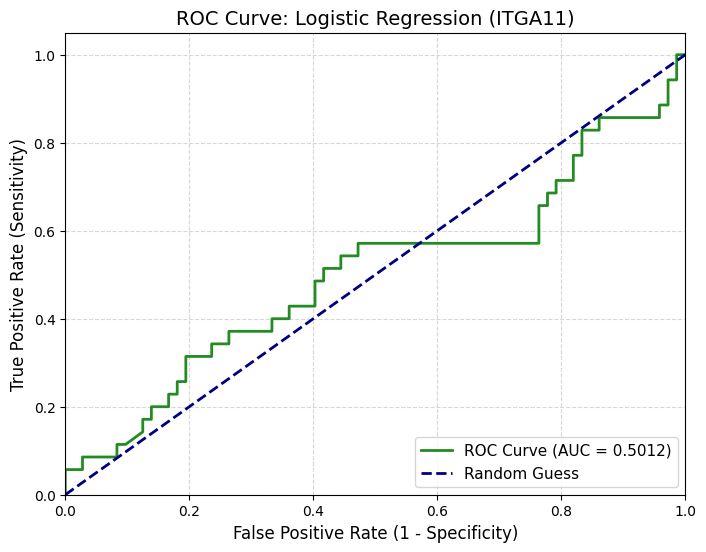

In [31]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Get prediction probabilities for the positive class ('Ovary')
ovary_index_11 = list(model_11.classes_).index('Ovary')
y_probs_11 = model_11.predict_proba(X_test_11)[:, ovary_index_11]

# Map the true labels to binary (1 for 'Ovary', 0 for 'Breast')
y_test_binary_11 = y_test_11.map({'Breast': 0, 'Ovary': 1})

# Calculate ROC metrics for ITGA11 model
fpr_11, tpr_11, thresholds_11 = roc_curve(y_test_binary_11, y_probs_11)
auc_score_11 = roc_auc_score(y_test_binary_11, y_probs_11)

# Plot the ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr_11, tpr_11, color='forestgreen', lw=2, label=f'ROC Curve (AUC = {auc_score_11:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
plt.title('ROC Curve: Logistic Regression (ITGA11)', fontsize=14)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()